# Quillan's hand count against the automatic counts

On a subset of samples Quillan clicked, by hand, **every AF488 cell near the junction line and every one that had migrated into the other organoid** (`Manual counts Quillan`, one dot per cell; all AF488, whatever channel the stored count names). He says himself the labelling is noisy: a dot means "I saw a positive cell here", and a cell without a dot may be negative or may just have been missed. So the clicks are **a second opinion, not ground truth**.

Each dot is matched to the nearest segmented cell within 7 µm (one to one, nearest pairs first; `C.load_dots`). The automatic counts use four positivity rules on AF488:

| rule | a cell is positive when |
|---|---|
| median + 3 SD (current) | brighter than median + 3 SD of the band's own cells (what the junction analysis does now) |
| median + 7 SD, filtered | the same with k = 7, on the channel less its local median (slow haze removed) |
| negative 99.9th pct | brighter than 99.9 % of the negative control: cells more than 300 µm deep in the organoid where AF488 is not at home |
| contrast, no autofl. | brighter against its own ring than 99 % of the negative control's cells are, and not as bright (for its ring) in AF555 — that would be autofluorescence |

**His region.** To compare like with like, the automatic count is made in the region he counted: cells within 50 µm of **his** line on either side, plus every cell past it into the organoid where AF488 is not at home (`C.region(..., "near + crossed", "second", LABEL)`; the first annotator's line where he drew none). Counts are given **per mm of his line**, so a long junction does not count for more.

Sections: (1) where the clicks are; (2) per sample, his count against each rule's; (3) cell by cell: which cells both call positive; (4) the genotype difference by hand and automatically; (5) whether it matters whose line defines the region.

In [1]:
import warnings
from pathlib import PureWindowsPath

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import count_common as C

cells, meta = C.load_all()
LABEL = C.label_channel(meta)
CHANNELS = meta["channels"].iloc[0]

ALL_RULES = C.rules(CHANNELS, LABEL)
RULES = {name: ALL_RULES[name] for name in [
    "band median + 3 SD (current)",
    "band median + 7 SD, median filter",
    "negative control 99.9th pct",
    "ring contrast > negative 99th pct, no autofluorescence",
]}
SHORT = dict(zip(RULES, ["median + 3 SD (current)", "median + 7 SD, filtered", "negative 99.9th pct",
                         "contrast, no autofl."]))
COLOURS = {"WT3": "tab:blue", "GD1": "tab:orange", "WT2": "tab:green"}
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)


def tidy(table, digits=2):
    # For display: numbers rounded, p values in scientific notation, columns of numbers stored as text made numeric.
    out = table.copy()
    for c in out.columns:
        values = pd.to_numeric(out[c], errors="coerce")
        if values.notna().sum() < out[c].notna().sum():
            continue
        if str(c).startswith("p ") or str(c).endswith(" p") or str(c).startswith("p ("):
            out[c] = [f"{v:.1e}" if np.isfinite(v) else "" for v in values]
        else:
            out[c] = values.astype(float).round(digits)
    return out


print(f"label channel {LABEL} (all channels {CHANNELS}); genotypes {meta['Genotype'].value_counts().to_dict()}")

NEAR_UM = 50.0
dots = C.load_dots(cells, meta)
HAVE = len(dots) > 0
counted = sorted(dots["name"].unique()) if HAVE else []


def line_of(name):
    # His own line where he drew one, the first annotator's otherwise (None: neither).
    bands = meta.loc[name, "bands"]
    return "second" if "second" in bands else ("first" if "first" in bands else None)


_calls = {}


def call(name, band, rule):
    # The rule's positive calls on every cell of the sample, with *band*'s threshold / negative control.
    key = (name, band, rule)
    if key not in _calls:
        _calls[key] = np.asarray(RULES[rule](cells[name], band), bool)
    return _calls[key]


def dot_region(d, df, band):
    # The dots in the region, by the dots' own positions: the same rule as C.region("near + crossed").
    signed = d[f"from {band} (um)"].to_numpy(float)
    away = -signed if C.home_is_band_side(df, LABEL, band) else signed
    beside = d[f"beside {band}"].fillna(False).to_numpy(bool)
    return beside & ((away > C.GAP_UM) | (np.abs(away) <= NEAR_UM))


if HAVE:
    print(f"{len(dots)} clicks on {len(counted)} of the {len(cells)} loaded samples; "
          f"matched to a segmented cell within {C.MATCH_UM:g} µm: {dots['matched'].mean():.0%}")
    print("regions on:", pd.Series([line_of(n) for n in counted]).value_counts().to_dict(), "line;",
          "genotypes:", meta.loc[counted, "Genotype"].value_counts().to_dict())
else:
    print("No clicks on the loaded samples: every section below is skipped.")

30 of 30 annotated samples measured, 919,868 cells; bands: first 30, second 27, automatic 26
label channel AF488 (all channels ['AF555', 'AF488']); genotypes {'GD1': 19, 'WT3': 11}


822 clicks on 12 of the 30 loaded samples; matched to a segmented cell within 7 µm: 86%
regions on: {'second': 12} line; genotypes: {'WT3': 7, 'GD1': 5}


## 1. Where the clicks are

Per sample: how many dots, the share **in his band**, **on his band's side** of his line, **more than 300 µm** past the line on that side (beyond the band), and the median distance of the dots to his line (+ into the band's side) and to the tissue edge (+ inside). Then the dots against every cell beside his line on the same samples, and against the cells in his band: medians and Mann-Whitney p for the distance to the line (unsigned) and to the edge.

**How to read the histograms:** density, so the shapes compare whatever the numbers. Left: signed distance to his line; dots piled near 0 mean he counted along the line; dots far to the right mean cells counted deep in the band's organoid; to the left, cells on the other side. Right: distance to the tissue edge; dots shifted towards 0 compared with all cells mean the positive cells sit along the surface.

,line,dots,matched,in his band,on the band's side,beyond 300 µm,"from the line, median (µm)","from the edge, median (µm)"
sample,,,,,,,,
020-019_s4,second,57.0,0.91,0.26,0.82,0.56,329.98,147.87
026-025_s4,second,92.0,0.97,0.36,0.46,0.09,-7.18,121.15
026-025_s8,second,95.0,0.94,0.46,0.64,0.16,19.88,121.88
031-030_s7,second,43.0,0.60,0.49,0.91,0.42,246.85,70.24
033-032_s12,second,106.0,0.79,0.50,0.83,0.33,175.61,32.37
034-033_s13,second,84.0,0.79,0.30,0.62,0.32,98.23,59.79
034-033_s17,second,75.0,0.77,0.35,0.67,0.31,55.44,54.54
039-038_s5,second,82.0,0.96,0.21,0.32,0.11,-44.16,130.47
045-044_s15,second,50.0,0.80,0.30,0.68,0.40,112.89,91.49


clicks beside the line: 720 of 822


,"clicks, median","every cell beside his line, median",p vs every cell beside his line,"cells in his band, median",p vs cells in his band
measure,,,,,
|distance to the line| (µm),95.0,489.0,1.6e-155,154.0,5.6e-06
distance to the edge (µm),118.0,245.0,3.1e-56,284.0,1.8e-73


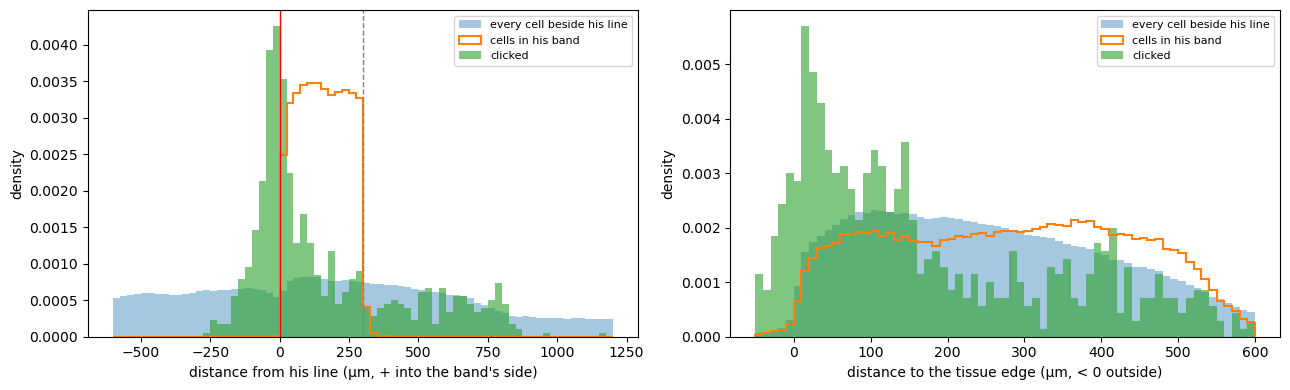

In [2]:
if HAVE:
    where = []
    for name in counted:
        band = line_of(name)
        d = dots[dots["name"] == name]
        signed = d[f"from {band} (um)"]
        where.append({"sample": C.short(name), "line": band, "dots": len(d), "matched": d["matched"].mean(),
                      "in his band": d[f"in {band}"].astype(float).mean() if f"in {band}" in d else np.nan,
                      "on the band's side": (signed > 0).mean(), "beyond 300 µm": (signed > 300).mean(),
                      "from the line, median (µm)": signed.median(), "from the edge, median (µm)": d["edge (um)"].median()})
    where = pd.DataFrame(where).set_index("sample")
    display(tidy(where))
    pooled = dots.assign(band=[line_of(n) for n in dots["name"]])
    pooled["from line"] = [r[f"from {r['band']} (um)"] for _, r in pooled.iterrows()]
    pooled["beside line"] = [bool(r[f"beside {r['band']}"]) for _, r in pooled.iterrows()]
    reference = {"every cell beside his line": [], "cells in his band": []}
    for name in counted:
        band, df = line_of(name), cells[name]
        sub = df[["edge (um)"]].assign(**{"from line": df[f"from {band} (um)"]})
        reference["every cell beside his line"].append(sub[df[f"beside {band}"].to_numpy()])
        reference["cells in his band"].append(sub[df[f"in {band}"].to_numpy()])
    reference = {k: pd.concat(v) for k, v in reference.items()}
    clicks = pooled.loc[pooled["beside line"], ["from line", "edge (um)"]]
    rows = []
    for key, column in (("|distance to the line| (µm)", "from line"), ("distance to the edge (µm)", "edge (um)")):
        a = clicks[column].abs() if column == "from line" else clicks[column]
        row = {"measure": key, "clicks, median": a.median()}
        for ref_name, ref in reference.items():
            b = ref[column].abs() if column == "from line" else ref[column]
            row[f"{ref_name}, median"] = b.median()
            row[f"p vs {ref_name}"] = stats.mannwhitneyu(a.dropna(), b.dropna()).pvalue if len(a.dropna()) and len(b) else np.nan
        rows.append(row)
    print(f"clicks beside the line: {len(clicks)} of {len(pooled)}")
    display(tidy(pd.DataFrame(rows).set_index("measure"), 0))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, column, bins, xlabel in (
            (axes[0], "from line", np.arange(-600, 1201, 25), "distance from his line (µm, + into the band's side)"),
            (axes[1], "edge (um)", np.arange(-50, 601, 10), "distance to the tissue edge (µm, < 0 outside)")):
        ax.hist(reference["every cell beside his line"][column], bins=bins, density=True, alpha=0.4,
                label="every cell beside his line")
        ax.hist(reference["cells in his band"][column], bins=bins, density=True, histtype="step", lw=1.5,
                label="cells in his band")
        ax.hist(clicks[column], bins=bins, density=True, alpha=0.6, label="clicked")
        ax.set_xlabel(xlabel); ax.set_ylabel("density"); ax.legend(fontsize=8)
    axes[0].axvline(0, color="red", lw=1); axes[0].axvline(300, color="grey", lw=1, ls="--")
    plt.tight_layout()
else:
    print("no clicks: skipped")

## 2. Per sample: his count against each rule's

Per sample, positives per mm of his line, in his region, for each rule, against his clicks per mm. His count is taken two ways: **all his clicks** (what he set out to count: near the line and crossed), and **only the clicks in the region** as the automatic count defines it (dot positions, the same rule) — if the two differ much, the region does not match what he counted.

Per rule, over samples: **Spearman** (do the two rank the samples the same way? the minimum for a usable stand-in), **CCC** (do they give the same number?) and the **median ratio** automatic / manual (1 = the same level; 2 = the rule counts twice as many).

**How to read the figure:** one panel per rule, one dot per sample coloured by genotype, log axes, the grey line where the two are equal. Dots along a line parallel to it rank the samples alike at a different level (fixable by the threshold); a shapeless cloud means the rule measures something else. A count of 0 is drawn at 0.5 per mm.

,Genotype,line,clicks per mm,clicks in region per mm,median + 3 SD (current),"median + 7 SD, filtered",negative 99.9th pct,"contrast, no autofl."
name,,,,,,,,
020-019_s4,WT3,second,41.1,26.7,257.2,47.6,13.0,110.2
026-025_s4,WT3,second,85.5,71.6,560.4,246.3,474.0,586.4
026-025_s8,WT3,second,79.4,73.6,532.6,277.6,625.5,661.4
031-030_s7,WT3,second,53.4,53.4,7.4,16.1,57.1,29.8
033-032_s12,WT3,second,68.0,46.8,152.7,101.4,44.3,118.7
034-033_s13,WT3,second,63.6,47.7,167.2,77.9,41.6,170.3
034-033_s17,WT3,second,48.2,28.3,77.2,28.3,67.5,86.8
039-038_s5,GD1,second,88.7,37.9,278.1,47.6,13.0,82.2
045-044_s15,GD1,second,36.4,26.2,61.9,7.3,104.2,59.7


,n,Spearman (all clicks),CCC (all clicks),"auto / manual, median (all clicks)",Spearman (clicks in region),CCC (clicks in region),"auto / manual, median (clicks in region)"
median + 3 SD (current),12.0,-0.01,-0.00,4.17,0.03,0.01,7.06
"median + 7 SD, filtered",12.0,0.78,0.30,0.87,0.73,0.28,1.44
negative 99.9th pct,12.0,0.12,0.10,1.23,0.18,0.12,1.48
"contrast, no autofl.",12.0,0.61,0.09,1.77,0.59,0.10,2.80


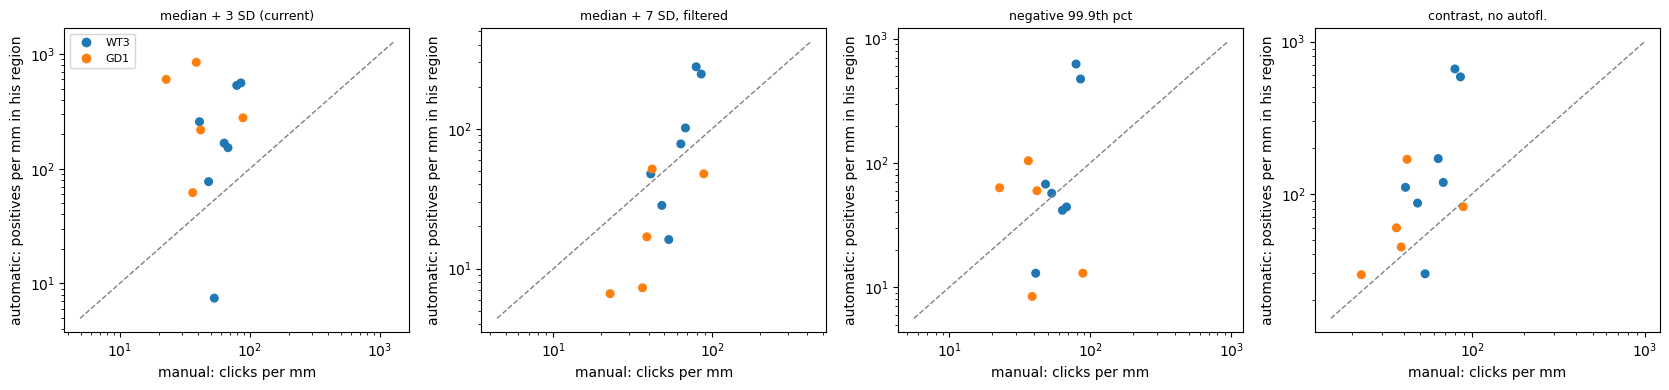

In [3]:
def tally(band_of):
    """Per sample and rule, in the region of *band_of[name]*: clicks, automatic count, TP / FP / FN."""
    rows = []
    for name, band in band_of.items():
        df, d = cells[name], dots[dots["name"] == name]
        region = C.region(df, "near + crossed", band, LABEL, near_um=NEAR_UM)
        d_region = dot_region(d, df, band)
        clicked = df["clicked"].to_numpy()
        unmatched = int((d_region & ~d["matched"].to_numpy(bool)).sum())
        length_mm = meta.loc[name, "lengths (um)"][band] / 1000
        base = {"name": name, "line": band, "Genotype": meta.loc[name, "Genotype"], "slide": meta.loc[name, "slide"],
                "length (mm)": length_mm, "clicks": len(d), "clicks in region": int(d_region.sum()),
                "clicks per mm": len(d) / length_mm, "clicks in region per mm": d_region.sum() / length_mm,
                "matched clicks in region": int((clicked & region).sum()), "unmatched clicks in region": unmatched}
        for rule in RULES:
            positive = call(name, band, rule) & region
            tp = int((positive & clicked).sum())
            rows.append({**base, "rule": SHORT[rule], "auto": int(positive.sum()), "auto per mm": positive.sum() / length_mm,
                         "TP": tp, "FP": int(positive.sum()) - tp,
                         "FN": int((clicked & region & ~positive).sum()) + unmatched})
    return pd.DataFrame(rows)


def agreement(t):
    out = {}
    for rule, g in t.groupby("rule", sort=False):
        row = {"n": len(g)}
        for manual in ("clicks per mm", "clicks in region per mm"):
            tag = "all clicks" if manual == "clicks per mm" else "clicks in region"
            ok = g[manual] > 0
            row[f"Spearman ({tag})"] = stats.spearmanr(g[manual], g["auto per mm"]).statistic if len(g) > 2 else np.nan
            row[f"CCC ({tag})"] = C.ccc(g[manual], g["auto per mm"])
            row[f"auto / manual, median ({tag})"] = (g.loc[ok, "auto per mm"] / g.loc[ok, manual]).median()
        out[rule] = row
    return pd.DataFrame(out).T


if HAVE:
    mine = tally({n: line_of(n) for n in counted if line_of(n)})
    per_sample = mine.pivot_table(index="name", columns="rule", values="auto per mm")[list(SHORT.values())]
    head = mine.drop_duplicates("name").set_index("name")[["Genotype", "line", "clicks per mm", "clicks in region per mm"]]
    display(head.join(per_sample).rename(index=C.short).round(1))
    display(agreement(mine).round(2))

    fig, axes = plt.subplots(1, len(RULES), figsize=(4.2 * len(RULES), 4), squeeze=False)
    for ax, rule in zip(axes[0], SHORT.values()):
        g = mine[mine["rule"] == rule]
        x, y = g["clicks per mm"].clip(lower=0.5), g["auto per mm"].clip(lower=0.5)
        ax.scatter(x, y, s=30, c=[COLOURS.get(v, "grey") for v in g["Genotype"]])
        lo, hi = min(x.min(), y.min()) / 1.5, max(x.max(), y.max()) * 1.5
        ax.plot([lo, hi], [lo, hi], color="grey", lw=1, ls="--")
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel("manual: clicks per mm"); ax.set_ylabel("automatic: positives per mm in his region")
        ax.set_title(rule, fontsize=9)
    handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=g) for g, c in COLOURS.items() if g in set(mine["Genotype"])]
    axes[0][0].legend(handles=handles, fontsize=8)
    plt.tight_layout()
else:
    print("no clicks: skipped")

## 3. Cell by cell: which cells both call positive

In his region, per rule, pooled over the counted samples:

- **TP** — cells the rule calls positive that he clicked;
- **FP** — cells the rule calls positive that he did not click;
- **FN** — his clicks in the region the rule does not call: clicked cells called negative, plus clicks with no segmented cell within 7 µm (those no rule can find).

**Precision** = TP / (TP + FP): of the rule's positives, the share he clicked. **Recall** = TP / (TP + FN): of his clicks, the share the rule finds. **F1** is their harmonic mean. The **ceiling** is the share of his clicks in the region that have a segmented cell under them: the most recall any rule can reach.

**Read precision with care.** His labelling is noisy and a positive cell he did not click counts as an FP here. A low precision may be cells he missed rather than cells the rule invents; a look at a few FPs on the images is the only way to tell. Recall is the safer number: a cell he clicked and the rule calls negative is a real disagreement (or a click on the wrong cell).

In [4]:
def prf(t):
    out = {}
    for rule, g in t.groupby("rule", sort=False):
        tp, fp, fn = g["TP"].sum(), g["FP"].sum(), g["FN"].sum()
        precision, recall = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
        per = g.assign(f1=2 * g["TP"] / (2 * g["TP"] + g["FP"] + g["FN"]).replace(0, np.nan))
        out[rule] = {"TP": tp, "FP": fp, "FN": fn, "precision": precision, "recall": recall,
                     "F1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
                     "F1 per sample, median": per["f1"].median()}
    return pd.DataFrame(out).T


if HAVE:
    one = mine.drop_duplicates("name")
    in_region = one["clicks in region"].sum()
    print(f"clicks in the region: {in_region} of {one['clicks'].sum()}; with a segmented cell under them "
          f"(the ceiling on recall): {one['matched clicks in region'].sum() / max(in_region, 1):.0%}")
    display(tidy(prf(mine)))
else:
    print("no clicks: skipped")

clicks in the region: 604 of 822; with a segmented cell under them (the ceiling on recall): 87%


,TP,FP,FN,precision,recall,F1,"F1 per sample, median"
median + 3 SD (current),344.0,4320.0,259.0,0.07,0.57,0.13,0.16
"median + 7 SD, filtered",331.0,808.0,272.0,0.29,0.55,0.38,0.37
negative 99.9th pct,261.0,1628.0,342.0,0.14,0.43,0.21,0.22
"contrast, no autofl.",270.0,2370.0,333.0,0.10,0.45,0.17,0.19


## 4. Genotype: does the automatic count replicate the manual difference?

His clicks per mm compared between genotypes (`C.compare_groups`: Mann-Whitney U, two-sided, for two genotypes; Kruskal-Wallis for more), on samples and on slide means (the safer unit: sections of one slide may be one assembloid), next to each rule's count **on the same samples** — and then each rule on **every loaded sample** (its region from his line where there is one, the first annotator's otherwise), which adds samples he did not count.

**How to read it:** the question is whether the automatic count goes **the same direction** as his (ratio on the same side of 1) and by **about as much** (a similar ratio). p is printed but with this many samples only a large difference can reach 0.05. The ratio is the second genotype's median over the first's (alphabetical); it is infinite where the first's median is 0.

**The figure:** one panel per count, one dot per counted sample, the bar the genotype's median.

ratio is WT3 / GD1


GD1 median  WT3 median         n  WT3 / GD1          test     p
samples         unit   count                                                                                   
counted (12)    sample clicks per mm                 38.80       63.57    5 vs 7       1.64  Mann-Whitney  0.15
                       clicks in region per mm       31.62       47.67    5 vs 7       1.51  Mann-Whitney  0.07
                       median + 3 SD (current)      278.06      167.24    5 vs 7       0.60  Mann-Whitney  0.34
                       median + 7 SD, filtered       16.87       77.94    5 vs 7       4.62  Mann-Whitney  0.11
                       negative 99.9th pct           59.80       57.07    5 vs 7       0.95  Mann-Whitney  0.64
                       contrast, no autofl.          59.74      118.67    5 vs 7       1.99  Mann-Whitney  0.11
                slide  clicks per mm                 38.80       55.90    5 vs 5       1.44  Mann-Whitney  0.22
                       clicks in region per mm       31.62       46.83    5 vs 5       1.48  Mann-Whitney  0.06
                       median + 3 SD (current)      278.06      152.67    5 vs 5       0.55  Mann-Whitney  0.31
                       median + 7 SD, filtered       16.87       53.12    5 vs 5       3.15  Mann-Whitney  0.15
                       negative 99.9th pct           59.80       54.58    5 vs 5       0.91  Mann-Whitney  1.00
                       contrast, no autofl.          59.74      118.67    5 vs 5       1.99  Mann-Whitney  0.31
all loaded (30) sample median + 3 SD (current)      115.93      167.24  19 vs 11       1.44  Mann-Whitney  0.30
                       median + 7 SD, filtered       12.27       47.55  19 vs 11       3.87  Mann-Whitney  0.00
                       negative 99.9th pct           59.80       53.57  19 vs 11       0.90  Mann-Whitney  0.67
                       contrast, no autofl.          66.49      130.56  19 vs 11       1.96  Mann-Whitney  0.01
                slide  median + 3 SD (current)      216.94      204.94   11 vs 8       0.94  Mann-Whitney  0.72
                       median + 7 SD, filtered       13.83       47.00   11 vs 8       3.40  Mann-Whitney  0.08
                       negative 99.9th pct           59.80       49.25   11 vs 8       0.82  Mann-Whitney  0.66
                       contrast, no autofl.          77.29      124.61   11 vs 8       1.61  Mann-Whitney  0.06

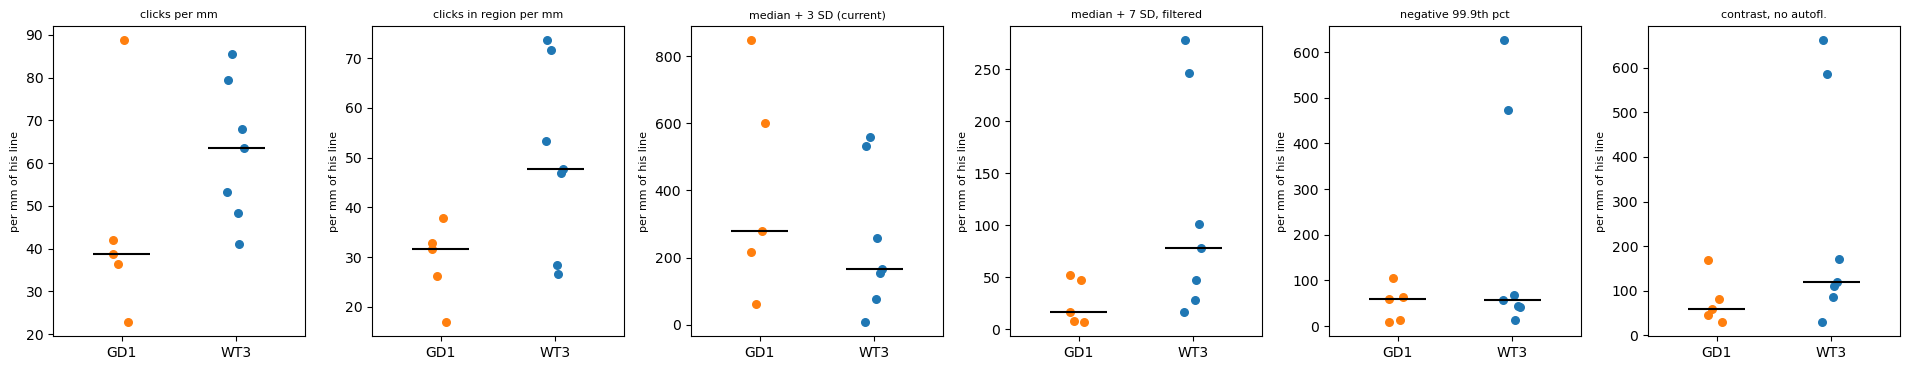

In [5]:
def genotype(frame, columns, scope):
    parts = []
    for unit in ("sample", "slide"):
        t = C.compare_groups(frame, columns, unit=unit)
        t.index = pd.MultiIndex.from_tuples([(scope, unit, c) for c in t.index], names=["samples", "unit", "count"])
        parts.append(t)
    return pd.concat(parts)


if HAVE:
    groups = sorted(meta["Genotype"].dropna().unique())
    print("ratio is", " / ".join(groups[:2][::-1]) if len(groups) == 2 else "not given (needs exactly two genotypes)")
    wide = head.join(per_sample).join(meta[["slide"]])
    hand_columns = ["clicks per mm", "clicks in region per mm", *SHORT.values()]
    tally_all = []
    for name in cells:
        band = line_of(name)
        if band is None:
            continue
        region = C.region(cells[name], "near + crossed", band, LABEL, near_um=NEAR_UM)
        length_mm = meta.loc[name, "lengths (um)"][band] / 1000
        tally_all.append({"name": name, "Genotype": meta.loc[name, "Genotype"], "slide": meta.loc[name, "slide"],
                          **{SHORT[r]: (call(name, band, r) & region).sum() / length_mm for r in RULES}})
    everyone = pd.DataFrame(tally_all).set_index("name")
    table = pd.concat([genotype(wide, hand_columns, f"counted ({len(wide)})"),
                       genotype(everyone, list(SHORT.values()), f"all loaded ({len(everyone)})")])
    display(tidy(table))

    fig, axes = plt.subplots(1, len(hand_columns), figsize=(3.2 * len(hand_columns), 3.8), squeeze=False)
    present = sorted(wide["Genotype"].dropna().unique())
    for ax, c in zip(axes[0], hand_columns):
        for x, g in enumerate(present):
            v = wide.loc[wide["Genotype"] == g, c]
            ax.scatter(np.full(len(v), x) + np.random.default_rng(0).uniform(-0.08, 0.08, len(v)), v,
                       color=COLOURS.get(g, "grey"), s=30)
            ax.hlines(v.median(), x - 0.25, x + 0.25, color="black")
        ax.set_xticks(range(len(present)), present); ax.set_xlim(-0.6, len(present) - 0.4)
        ax.set_title(c, fontsize=8); ax.set_ylabel("per mm of his line", fontsize=8)
    plt.tight_layout()
else:
    print("no clicks: skipped")

## 5. Does it matter whose line defines the region?

On the counted samples that have both hand-drawn lines, the whole comparison is run twice: the region (and the per-mm length, and the rules' band and negative control) from the **first** annotator's line, then from **Quillan's** (second). His clicks were made against his own line, so his line should fit them better: more of his clicks inside the region, and a closer match. If the first annotator's line does about as well, the comparison does not hinge on who drew the junction.

**How to read it:** per rule and line, the share of his clicks that fall in the region, the per-sample agreement (Spearman, CCC, median ratio, against all his clicks per mm) and the cell-level precision, recall and F1. Compare the two rows of each rule.

In [6]:
if HAVE:
    both = [n for n in counted if {"first", "second"} <= set(meta.loc[n, "bands"])]
    print(f"counted samples with both lines: {len(both)}")
    if len(both) >= 2:
        rows = []
        for band in ("first", "second"):
            t = tally({n: band for n in both})
            one = t.drop_duplicates("name")
            a, p = agreement(t), prf(t)
            for rule in SHORT.values():
                rows.append({"rule": rule, "line": band,
                             "clicks in region (share)": one["clicks in region"].sum() / max(one["clicks"].sum(), 1),
                             "clicks per mm, median": one["clicks per mm"].median(),
                             "auto per mm, median": t.loc[t["rule"] == rule, "auto per mm"].median(),
                             "Spearman": a.loc[rule, "Spearman (all clicks)"], "CCC": a.loc[rule, "CCC (all clicks)"],
                             "auto / manual": a.loc[rule, "auto / manual, median (all clicks)"],
                             "precision": p.loc[rule, "precision"], "recall": p.loc[rule, "recall"], "F1": p.loc[rule, "F1"]})
        display(pd.DataFrame(rows).set_index(["rule", "line"]).round(2))
    else:
        print("fewer than 2: skipped")
else:
    print("no clicks: skipped")

counted samples with both lines: 12


,,clicks in region (share),"clicks per mm, median","auto per mm, median",Spearman,CCC,auto / manual,precision,recall,F1
rule,line,,,,,,,,,
median + 3 SD (current),first,0.74,50.21,192.25,-0.10,0.00,3.90,0.08,0.59,0.14
"median + 7 SD, filtered",first,0.74,50.21,47.43,0.87,0.33,0.88,0.28,0.55,0.37
negative 99.9th pct,first,0.74,50.21,47.91,0.38,0.11,0.87,0.14,0.42,0.21
"contrast, no autofl.",first,0.74,50.21,92.31,0.68,0.11,1.83,0.11,0.45,0.17
median + 3 SD (current),second,0.73,50.80,237.56,-0.01,-0.00,4.17,0.07,0.57,0.13
"median + 7 SD, filtered",second,0.73,50.80,47.58,0.78,0.30,0.87,0.29,0.55,0.38
negative 99.9th pct,second,0.73,50.80,58.44,0.12,0.10,1.23,0.14,0.43,0.21
"contrast, no autofl.",second,0.73,50.80,98.53,0.61,0.09,1.77,0.10,0.45,0.17


### What it showed (21 October 2026: 12 samples, 822 clicks)

**Where the clicks are.** Closer to the line (median 95 vs 154 µm for the band's cells) and much closer to the tissue edge (118 vs 284 µm; p ≈ 1e-73): migrating AF488 cells travel along the surface. 87 % of clicks in his region have a segmented nucleus under them.

**Per sample** (cells per mm in his region): the current rule does not follow him at all (Spearman −0.01, 4–7× his count); **median + 7 SD, median filter follows him** (Spearman 0.78, median 0.87× his count); ring contrast without autofluorescence partly (0.61, 1.8×).

**Cell by cell:** median + 7 SD filtered: precision 0.29, recall 0.55, F1 0.38; the current rule 0.07 / 0.57 / 0.13 (4 320 cells called that he did not click).

**Genotype (WT3 / GD1):**

| | 12 counted, samples | 12 counted, slides | all 30, samples | all 30, slides |
|---|---|---|---|---|
| manual, clicks per mm | 1.64× (p 0.15) | 1.44× (p 0.22) | — | — |
| median + 7 SD, filtered | 4.6× (p 0.11) | 3.2× (p 0.15) | 3.9× (p 0.001) | 3.4× (p 0.08) |
| ring contrast, no autofl. | 2.0× (p 0.11) | 2.0× (p 0.31) | 2.0× (p 0.01) | 1.6× (p 0.06) |
| median + 3 SD (current) | 0.60× (p 0.34) | 0.55× (p 0.31) | 1.4× (p 0.30) | 0.94× (p 0.72) |

- The calibrated rule and the contrast rule **replicate the direction** of the manual count (WT3 > GD1); the current rule does not (it even reverses on the counted 12).
- The automatic difference is larger than the manual one (3–5× vs 1.5×): either the rule is stricter where few cells cross (GD1), or the clicks include dimmer cells that the rule leaves out. Not resolved by these data.
- Whose line defines his region hardly matters (F1 0.37 first, 0.38 his own).